Saving original dataset.csv to original dataset.csv
Dataset loaded successfully!
(5000, 12)
   order_id  order_date  customer_id product_category region  quantity  \
0     10001  01-01-2022         1102           Beauty  South         7   
1     10002  01-02-2022         1435         Clothing  South         7   
2     10003  01-03-2022         1860           Beauty   East         3   
3     10004  01-04-2022         1270      Electronics   West         5   
4     10005  01-05-2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31            COD              6              2.5   
3      524.47      0.02         Wallet              6              1.6   
4      139.87      0.33         Wallet              4              4.9   

   revenue  
0  18

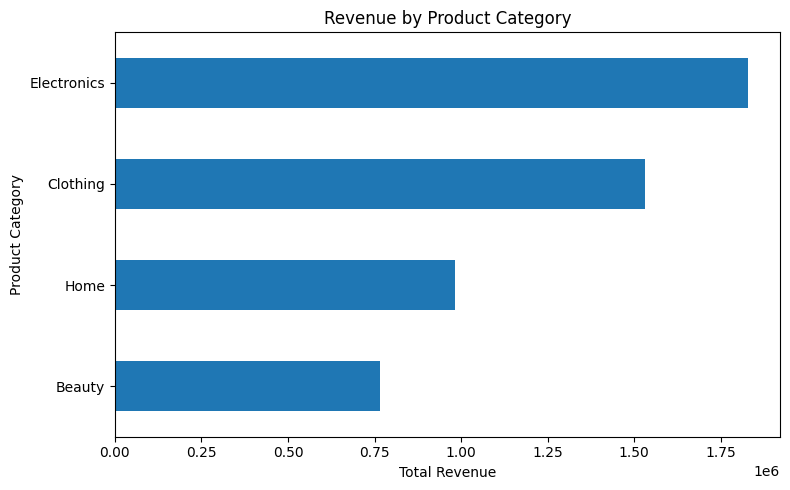


Revenue by Product Category:
product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64


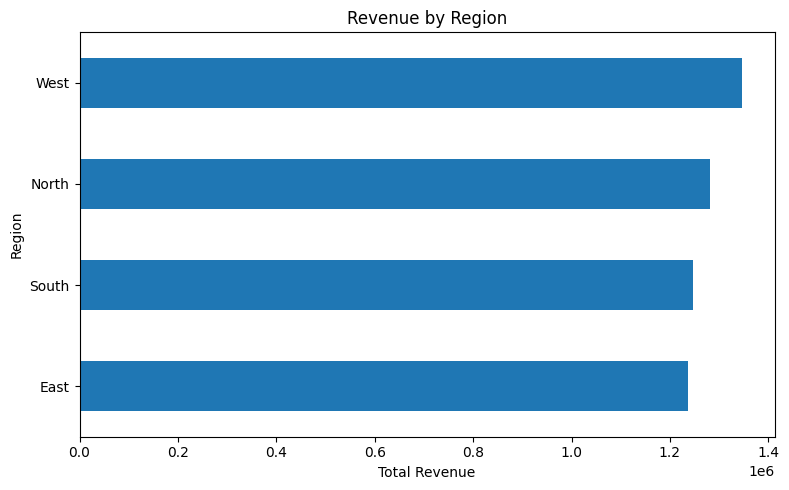


Revenue by Region:
region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64


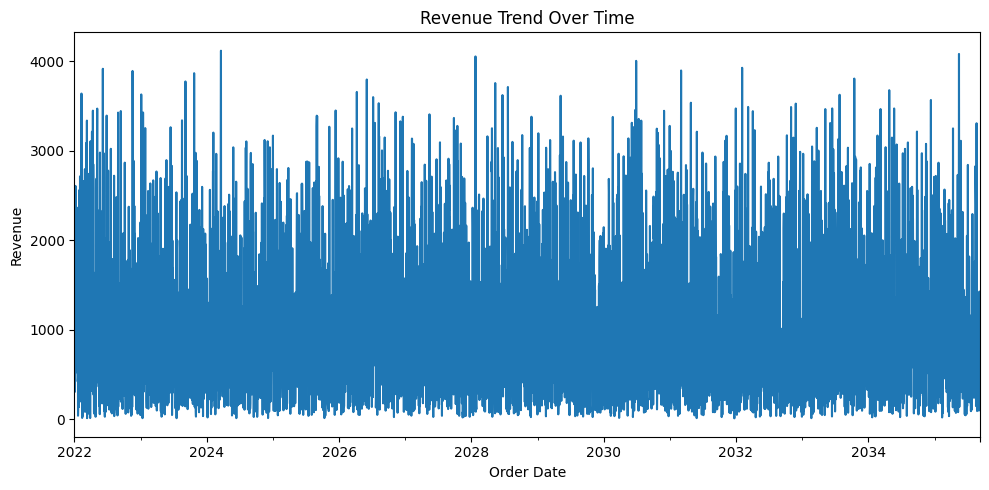

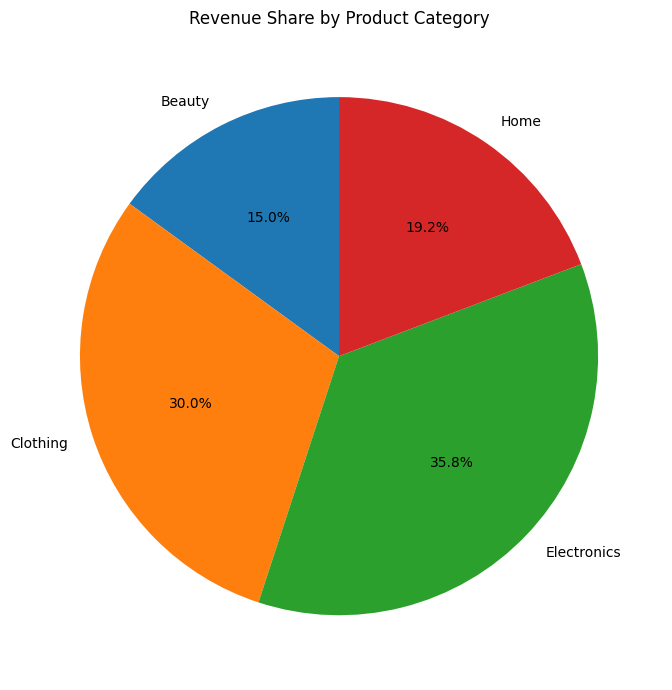

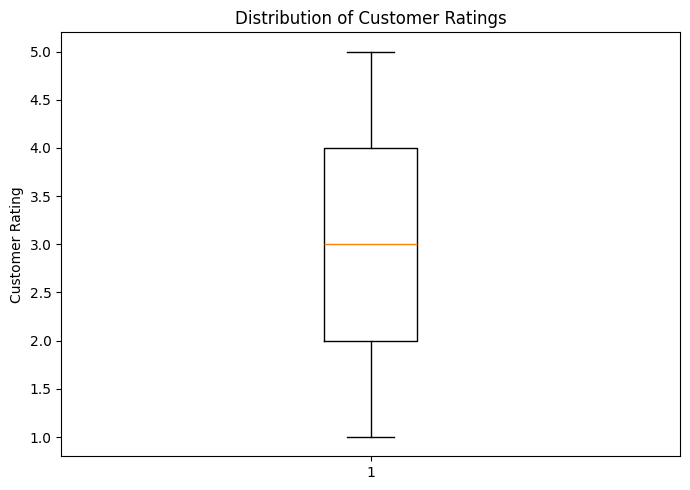

In [1]:
# E-commerce Sales Data Analysis

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 2. Upload and Load Dataset
uploaded = files.upload()
df = pd.read_csv("original dataset.csv")

print("Dataset loaded successfully!")
print(df.shape)
print(df.head())
df.info()

# 3. Dataset Information
print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

# 4. Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check and Remove Duplicate Records
duplicate_count = df.duplicated().sum()
print("\nNumber of duplicate records:", duplicate_count)

df = df.drop_duplicates()

print("\nDataset after removing duplicates:")
print(df.head().to_string(index=False))

# 6. Convert Order Date
df["order_date"] = pd.to_datetime(
    df["order_date"], format="mixed", dayfirst=False
)
print(df["order_date"].head())

# Sort data by date
df = df.sort_values("order_date")

# 7. Overall Sales Analysis
total_revenue = df["revenue"].sum()
total_quantity = df["quantity"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()

print("\n===== SALES SUMMARY =====")
print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
#8. Revenue by Product Category - Bar Chart
category_revenue = df.groupby(
    "product_category"
)["revenue"].sum().sort_values()

plt.figure(figsize=(8, 5))
category_revenue.plot(kind="barh")
plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

print("\nRevenue by Product Category:")
print(category_revenue.sort_values(ascending=False))
# 10. Revenue by Region - Bar Chart
region_revenue = df.groupby("region")["revenue"].sum().sort_values()

plt.figure(figsize=(8, 5))
region_revenue.plot(kind="barh")
plt.title("Revenue by Region")
plt.xlabel("Total Revenue")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

print("\nRevenue by Region:")
print(region_revenue.sort_values(ascending=False))
# 9. Revenue Trend Over Time - Line Chart
date_revenue = df.groupby("order_date")["revenue"].sum()

plt.figure(figsize=(10, 5))
date_revenue.plot()
plt.title("Revenue Trend Over Time")
plt.xlabel("Order Date")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()
# 11. Category Contribution - Pie Chart
category_revenue = df.groupby(
    "product_category"
)["revenue"].sum()

plt.figure(figsize=(7, 7))
category_revenue.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue Share by Product Category")
plt.ylabel("")
plt.tight_layout()
plt.show()
# 12. Distribution of Customer Ratings - Box Plot
plt.figure(figsize=(7, 5))
plt.boxplot(df["customer_rating"].dropna())
plt.title("Distribution of Customer Ratings")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.show()